# 06 - Tiered Pricing Scenarios - H1a, H1b

**Inputs:** `salon_clean.csv`, `tiers.json`, `service_clusters.csv`, `scenarios.py`, `pricing.py`

1. Count bookings per week x cluster x demand tier

2. Grid-search a peak premium and off-peak discount (0-20%, 5% steps) per cluster

   on the 31 TRAINING weeks, maximizing base-scenario revenue (Task 2 C4)

3. Evaluate flat vs tiered pricing on the 13 HOLDOUT weeks under all three scenarios

4. Test H1a (off-peak share) and H1b (revenue) with one-sided Wilcoxon + Holm correction

**Assumptions:** revenue is an index (base price = 1.0); free consultations weight 0 and
are not repriced. All hour bookings count as demand (cancellation rates are
similar across tiers, 11.5-14.8%, so this does not bias the flat-vs-tiered comparison

In [1]:
import sys, json; sys.path.append("..")
from itertools import product
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scenarios import SCENARIOS, PRICE_GRID, TRAIN_FRAC, SEED
from pricing import apply_pricing, revenue, evaluate

s = pd.read_csv("../data/processed/salon_clean.csv")
TIER = {int(k): v for k, v in json.load(open("../outputs/tables/tiers.json")).items()}
clus = pd.read_csv("../outputs/tables/service_clusters.csv", index_col=0)
CLUSTER_OF = clus["cluster"].to_dict()
NAME_OF = clus.groupby("cluster")["cluster_name"].first().to_dict()

# Hour-valid bookings only (the 1:00 record has no tier)
b = s[s["hour_valid"]].copy()
b["tier"] = b["appt_hour"].astype(int).map(TIER)
b["cluster"] = b["service_group"].map(CLUSTER_OF)
assert b["cluster"].notna().all(), "A service_group is missing from service_clusters.csv"
b["cluster"] = b["cluster"].astype(int)

n_weeks = int(s["week_index"].max()) + 1
n_train = int(round(n_weeks * TRAIN_FRAC))
CLUSTERS = sorted(b["cluster"].unique())          # -1 consultation + 0..3

# Week x cluster x tier counts, every combination present (zeros kept)
counts = (b.groupby(["week_index", "cluster", "tier"]).size()
           .unstack(fill_value=0)
           .reindex(pd.MultiIndex.from_product([range(n_weeks), CLUSTERS],
                                               names=["week_index", "cluster"]),
                    fill_value=0)[["peak", "mid", "off"]])
train_counts = counts.loc[(slice(0, n_train - 1), slice(None)), :]
test_counts  = counts.loc[(slice(n_train, n_weeks - 1), slice(None)), :]

WEIGHTS = {-1: 0.0}                               # consultations earn $0; others 1.0

print("Bookings counted:", int(counts.values.sum()))          
print("Train weeks:", n_train, "| holdout weeks:", n_weeks - n_train)
print("\nTraining totals by cluster and tier:")
print(train_counts.groupby("cluster").sum().rename(index=NAME_OF))

Bookings counted: 185
Train weeks: 31 | holdout weeks: 13

Training totals by cluster and tier:
tier                       peak  mid  off
cluster                                  
Not clustered (free)          0    3    0
High-volume / high-cancel    22   13   13
Off-peak flexible             4    8    5
Planned-ahead                20   16   14
Peak-driven color            16    7    3


In [2]:
# Grid search abilty for each cluster, try every premium x discount on training weeks
# and keep the combination with the highest base-scenario revenue
# Tie-break: smaller total adjustment - less disruption to clients
base = SCENARIOS["base"]
train_by_cluster = train_counts.groupby("cluster").sum()

rows, POLICY_GRID = [], {}
for c in CLUSTERS:
    if c == -1:                                   
        continue
    pk, md, of = train_by_cluster.loc[c, ["peak", "mid", "off"]]
    flat = revenue(pk, md, of)
    best = None
    for p, d in product(PRICE_GRID, PRICE_GRID):
        npk, nmd, nof = apply_pricing(pk, md, of, p, d, base["e_prem"], base["e_disc"], base["shift_share"])
        rev = revenue(npk, nmd, nof, p, d)
        key = (round(rev, 9), -(p + d))
        if best is None or key > best[0]:
            best = (key, p, d, rev)
    _, p, d, rev = best
    POLICY_GRID[c] = (p, d)
    rows.append({"cluster": NAME_OF[c], "premium": f"+{p:.0%}", "discount": f"-{d:.0%}",
                 "train_rev_change": f"{(rev - flat) / flat:+.1%}"})

print(pd.DataFrame(rows).to_string(index=False))

                  cluster premium discount train_rev_change
High-volume / high-cancel    +20%      -0%            +4.7%
        Off-peak flexible    +20%      -0%            +2.4%
            Planned-ahead    +20%      -0%            +4.1%
        Peak-driven color    +20%      -0%            +6.3%


In [3]:
# Policies
POLICY_B = {0: (0.10, 0.00),    # High-volume / high-cancel: +10% peak
            1: (0.00, 0.10),    # Off-peak flexible: -10% off-peak
            2: (0.10, 0.00),    # Planned-ahead: +10% peak
            3: (0.10, 0.00)}    # Peak-driven color: +10% peak
POLICIES = {"A: grid": POLICY_GRID, "B: targeted": POLICY_B}

def boot_median_ci(x, n=10_000):
    rng = np.random.default_rng(SEED)
    x = np.asarray(x)[~np.isnan(x)]
    meds = np.median(rng.choice(x, size=(n, len(x)), replace=True), axis=1)
    return np.percentile(meds, [2.5, 97.5])

results, summary = {}, []
for pname, pol in POLICIES.items():
    for sname, sc in SCENARIOS.items():
        wk = evaluate(test_counts, pol, sc, WEIGHTS)
        results[(pname, sname)] = wk
        sh = wk.dropna(subset=["flat_share"])
        rv = wk.dropna(subset=["rev_pct_change"])
        lo, hi = boot_median_ci(rv["rev_pct_change"])
        summary.append({
            "policy": pname, "scenario": sname,
            "weeks_used": len(sh),
            "offshare_flat_%": sh["flat_share"].median() * 100,
            "offshare_tier_%": sh["tier_share"].median() * 100,
            "offshare_change_pts": (sh["tier_share"] - sh["flat_share"]).median() * 100,
            "median_rev_change_%": rv["rev_pct_change"].median(),
            "rev_CI95_low": lo, "rev_CI95_high": hi,
            "total_rev_change_%": (wk["tier_rev"].sum() - wk["flat_rev"].sum()) / wk["flat_rev"].sum() * 100,
        })
summary = pd.DataFrame(summary)
print("Holdout weeks excluded (no bookings):", (n_weeks - n_train) - summary["weeks_used"].iloc[0])
print(summary.round(2).to_string(index=False))
summary.to_csv("../outputs/tables/scenario_summary.csv", index=False)

Holdout weeks excluded (no bookings): 1
     policy     scenario  weeks_used  offshare_flat_%  offshare_tier_%  offshare_change_pts  median_rev_change_%  rev_CI95_low  rev_CI95_high  total_rev_change_%
    A: grid conservative          12             30.0            33.73                 4.86                 2.68           0.0           3.35                2.75
    A: grid         base          12             30.0            32.72                 3.54                 4.08           0.0           5.10                4.18
    A: grid   optimistic          12             30.0            32.21                 2.87                 4.81           0.0           6.01                4.93
B: targeted conservative          12             30.0            31.83                 2.13                 1.40           0.0           1.94                1.53
B: targeted         base          12             30.0            31.35                 1.56                 1.88           0.0           2.61         

In [4]:
# Hypothesis tests (pre-registered: Policy A, base scenario, holdout weeks)
from statsmodels.stats.multitest import multipletests

wk = results[("A: grid", "base")]
sh = wk.dropna(subset=["flat_share"])
rv = wk[wk["flat_rev"] > 0]

d_share = sh["tier_share"] - sh["flat_share"]
d_rev = rv["tier_rev"] - rv["flat_rev"]
print(f"H1a pairs: {len(d_share)} weeks, {int((d_share != 0).sum())} non-zero differences")
print(f"H1b pairs: {len(d_rev)} weeks, {int((d_rev != 0).sum())} non-zero differences")

pa = stats.wilcoxon(sh["tier_share"], sh["flat_share"], alternative="greater", zero_method="wilcox").pvalue
pb = stats.wilcoxon(rv["tier_rev"], rv["flat_rev"], alternative="greater", zero_method="wilcox").pvalue
reject, p_holm, _, _ = multipletests([pa, pb], alpha=0.05, method="holm")

print(f"\nH1a off-peak share: raw p = {pa:.4f}, Holm p = {p_holm[0]:.4f}, reject H0a: {reject[0]}")
print(f"H1b revenue index:  raw p = {pb:.4f}, Holm p = {p_holm[1]:.4f}, reject H0b: {reject[1]}")

# C4 assumption: differences roughly symmetric around the median
for label, d in [("share (pts)", d_share * 100), ("revenue", d_rev)]:
    nz = d[d != 0]
    print(f"{label}: median {np.median(nz):.3f}, mean {nz.mean():.3f}, skew {stats.skew(nz):.2f}")

H1a pairs: 12 weeks, 8 non-zero differences
H1b pairs: 12 weeks, 8 non-zero differences

H1a off-peak share: raw p = 0.0039, Holm p = 0.0078, reject H0a: True
H1b revenue index:  raw p = 0.0039, Holm p = 0.0078, reject H0b: True
share (pts): median 4.209, mean 4.094, skew -0.51
revenue: median 0.204, mean 0.204, skew -0.00


In [5]:
# C5 practical significance scorecard
def scorecard(pname, policy):
    row = lambda sc: summary[(summary.policy == pname) & (summary.scenario == sc)].iloc[0]
    base_r, cons_r = row("base"), row("conservative")
    max_adj = max(max(p, d) for p, d in policy.values())
    return pd.DataFrame([
        ["1 Base off-peak share increase", ">= 3 pts", f"{base_r['offshare_change_pts']:.2f} pts", base_r["offshare_change_pts"] >= 3],
        ["2 Base revenue increase",        ">= 3%",    f"{base_r['median_rev_change_%']:.2f}%",   base_r["median_rev_change_%"] >= 3],
        ["3 Conservative revenue >= flat", ">= 0%",    f"{cons_r['median_rev_change_%']:.2f}%",   cons_r["median_rev_change_%"] >= 0],
        ["4 Adjustments within +/-20%",    "<= 20%",   f"{max_adj:.0%}",                          max_adj <= 0.20],
        ["5 Written rec per cluster",      "yes",      "report section F2",                       True],
    ], columns=["criterion", "target", "result", "met"])

for pname, pol in POLICIES.items():
    print(f"\n{pname}")
    print(scorecard(pname, pol).to_string(index=False))


A: grid
                     criterion   target            result  met
1 Base off-peak share increase >= 3 pts          3.54 pts True
       2 Base revenue increase    >= 3%             4.08% True
3 Conservative revenue >= flat    >= 0%             2.68% True
   4 Adjustments within +/-20%   <= 20%               20% True
     5 Written rec per cluster      yes report section F2 True

B: targeted
                     criterion   target            result   met
1 Base off-peak share increase >= 3 pts          1.56 pts False
       2 Base revenue increase    >= 3%             1.88% False
3 Conservative revenue >= flat    >= 0%             1.40%  True
   4 Adjustments within +/-20%   <= 20%               10%  True
     5 Written rec per cluster      yes report section F2  True


In [6]:
# Per cluster recs (C5 / 5): adjustments, hrs, rev range across scenarios
PEAK_H = ", ".join(f"{h}:00" for h, t in sorted(TIER.items()) if t == "peak")
OFF_H  = ", ".join(f"{h}:00" for h, t in sorted(TIER.items()) if t == "off")

rec_rows = []
for pname, pol in POLICIES.items():
    for c, (p, d) in pol.items():
        sub = test_counts[test_counts.index.get_level_values("cluster") == c]
        chg = []
        for sname in ["conservative", "base", "optimistic"]:
            wk = evaluate(sub, pol, SCENARIOS[sname], WEIGHTS)
            chg.append((wk["tier_rev"].sum() - wk["flat_rev"].sum()) / wk["flat_rev"].sum() * 100)
        rec_rows.append({
            "policy": pname, "cluster": NAME_OF[c],
            "peak premium": f"+{p:.0%} ({PEAK_H})" if p else "none",
            "off-peak discount": f"-{d:.0%} ({OFF_H})" if d else "none",
            "revenue change (cons / base / opt)": " / ".join(f"{x:+.1f}%" for x in chg),
        })
recs = pd.DataFrame(rec_rows)
print(recs.to_string(index=False))
recs.to_csv("../outputs/tables/cluster_recommendations.csv", index=False)

     policy                   cluster              peak premium          off-peak discount revenue change (cons / base / opt)
    A: grid High-volume / high-cancel +20% (9:00, 10:00, 12:00)                       none              +1.0% / +1.5% / +1.7%
    A: grid         Off-peak flexible +20% (9:00, 10:00, 12:00)                       none              +1.7% / +2.6% / +3.0%
    A: grid             Planned-ahead +20% (9:00, 10:00, 12:00)                       none              +2.7% / +4.1% / +4.8%
    A: grid         Peak-driven color +20% (9:00, 10:00, 12:00)                       none              +4.1% / +6.3% / +7.4%
B: targeted High-volume / high-cancel +10% (9:00, 10:00, 12:00)                       none              +0.6% / +0.8% / +0.9%
B: targeted         Off-peak flexible                      none -10% (13:00, 15:00, 17:00)              -1.2% / -0.9% / -0.4%
B: targeted             Planned-ahead +10% (9:00, 10:00, 12:00)                       none              +1.7% / +2.3% 

In [7]:
# Sensitivity (C4): illustrative relative price weights by cluster instead of 1.0 for all
# (color services usually cost more than haircut). Owners use their own prices in practical setting.
WEIGHTS_ALT = {-1: 0.0, 0: 1.0, 1: 2.0, 2: 1.5, 3: 2.0}
for pname, pol in POLICIES.items():
    for wname, w in [("equal weights", WEIGHTS), ("illustrative weights", WEIGHTS_ALT)]:
        wk = evaluate(test_counts, pol, SCENARIOS["base"], w)
        tot = (wk["tier_rev"].sum() - wk["flat_rev"].sum()) / wk["flat_rev"].sum() * 100
        print(f"{pname:12s} | {wname:20s} | base total revenue change {tot:+.2f}%")
# Grid optimum per cluster does not depend on weights: weight multiplies flat and tiered
# revenue equally within a cluster, so the best (premium, discount) is unchanged.

A: grid      | equal weights        | base total revenue change +4.18%
A: grid      | illustrative weights | base total revenue change +4.50%
B: targeted  | equal weights        | base total revenue change +2.14%
B: targeted  | illustrative weights | base total revenue change +2.26%


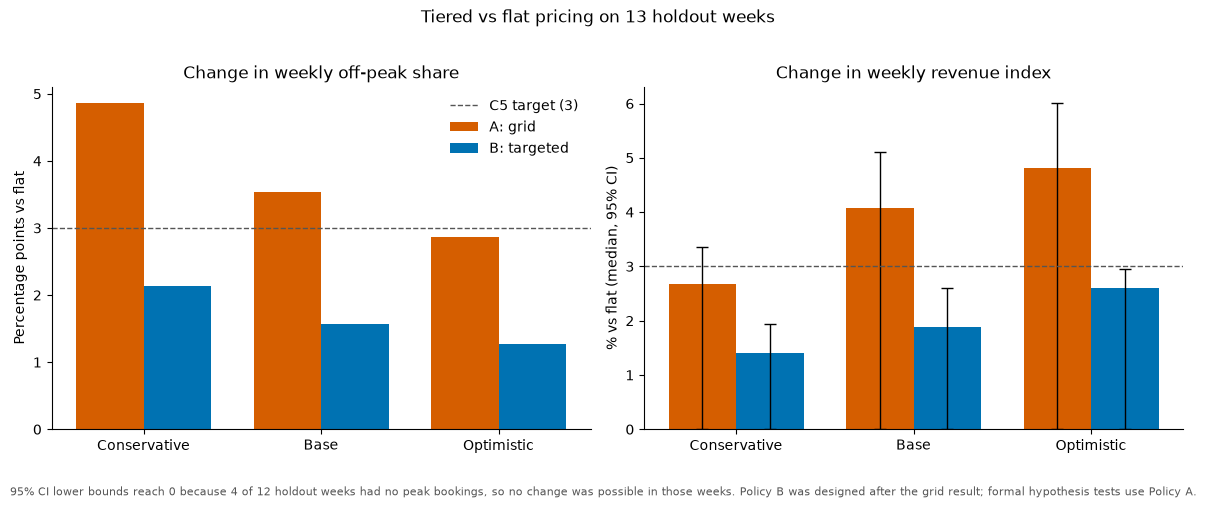

In [8]:
# Flat vs tiered comparison chart - C6
sc_order = ["conservative", "base", "optimistic"]
x = np.arange(len(sc_order)); w = 0.38
POL_COLORS = {"A: grid": "#D55E00", "B: targeted": "#0072B2"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for i, (pname, col) in enumerate(POL_COLORS.items()):
    d = summary[summary.policy == pname].set_index("scenario").loc[sc_order]
    axes[0].bar(x + (i - 0.5) * w, d["offshare_change_pts"], w, color=col, label=pname)
    err = [d["median_rev_change_%"] - d["rev_CI95_low"], d["rev_CI95_high"] - d["median_rev_change_%"]]
    axes[1].bar(x + (i - 0.5) * w, d["median_rev_change_%"], w, color=col, label=pname,
                yerr=err, capsize=4, error_kw={"elinewidth": 1})
for ax, title, ylab in [(axes[0], "Change in weekly off-peak share", "Percentage points vs flat"),
                        (axes[1], "Change in weekly revenue index", "% vs flat (median, 95% CI)")]:
    ax.axhline(3, ls="--", color="#555555", lw=1, label="C5 target (3)")
    ax.set(title=title, ylabel=ylab, xticks=x, xticklabels=[s.title() for s in sc_order])
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
fig.suptitle("Tiered vs flat pricing on 13 holdout weeks", y=1.02)
fig.text(0.01, -0.06, "95% CI lower bounds reach 0 because 4 of 12 holdout weeks had no peak bookings, "
         "so no change was possible in those weeks. Policy B was designed after the grid result; "
         "formal hypothesis tests use Policy A.", fontsize=8, color="#555555")
fig.tight_layout()
fig.savefig("../outputs/figures/fig07_scenarios.png", dpi=200, bbox_inches="tight")
plt.show()

## Findings and Insights

- Grid search (training, base) chose +20% peak / 0% off-peak for every cluster: elasticities are
  inelastic and identical across clusters, so clusters change how much a premium earns, not which price is optimal

- Policy A (grid), holdout: off-peak share +4.86 / +3.54 / +2.87 pts; revenue +2.68 / +4.08 / +4.81%
  (cons / base / opt). C5 scorecard 5/5

- H1a and H1b supported: one-sided Wilcoxon p = 0.0039 (Holm 0.0078), 8 non-zero weeks; p reflects
  consistency under the assumptions, not observed client response

- Policy B (targeted, ±10%): revenue +1.40 / +1.88 / +2.60%; C5 scorecard 3/5

- Peak-driven color gains most (+6.3% base under A); off-peak discount loses revenue in every scenario

- Conclusions robust to illustrative price weights (+4.18% to +4.50% under A)